# Model soups with held-out selection

Average compatible checkpoints and compare uniform and greedy soups on unseen data.

Train ridge models with common features on several overlapping in-distribution samples and one shifted sample. Rank candidates by validation error. Accept an addition only when the running soup improves on validation. Evaluate the frozen selection on an independent test set.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

greedy members [3] test MSE [0.367 0.426 0.367]


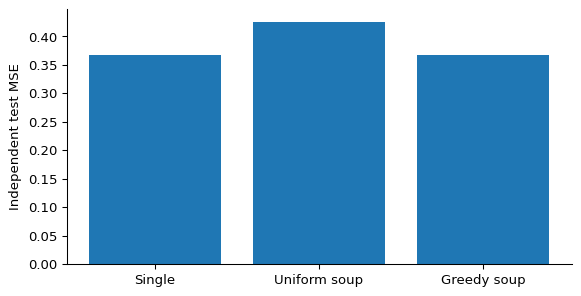

In [2]:
rng = np.random.default_rng(27)
w0 = np.array([1.0, -0.8, 0.55])
X = rng.normal(size=(210, 3))
y = X @ w0 + rng.normal(0, 0.55, len(X))
V = rng.normal(size=(180, 3))
vy = V @ w0 + rng.normal(0, 0.55, len(V))
T = rng.normal(size=(230, 3))
ty = T @ w0 + rng.normal(0, 0.55, len(T))
weights = []
for j in range(6):
    ix = rng.choice(len(X), 75, replace=False)
    target = y[ix] + (2 * X[ix, 0] if j == 5 else 0)
    weights.append(Ridge(alpha=2, fit_intercept=False).fit(X[ix], target).coef_)
weights = np.array(weights)
loss = lambda X, y, w: np.mean((X @ w - y) ** 2)
order = sorted(range(6), key=lambda i: loss(V, vy, weights[i]))
chosen = [order[0]]
for i in order[1:]:
    if loss(V, vy, weights[chosen + [i]].mean(0)) < loss(V, vy, weights[chosen].mean(0)):
        chosen.append(i)
candidates = [weights[order[0]], weights.mean(0), weights[chosen].mean(0)]
scores = [loss(T, ty, v) for v in candidates]
print("greedy members", chosen, "test MSE", np.round(scores, 3))
assert np.allclose(T @ weights.mean(0), (T @ weights.T).mean(1))
fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
ax.bar(["Single", "Uniform soup", "Greedy soup"], scores)
ax.set(ylabel="Independent test MSE")
plt.show()

## Interpreting the result

In a linear model, averaging weights and averaging predictions coincide. For nonlinear networks this identity generally fails. Validation reuse can also overfit a small validation set.

## Exercise

Repeat the experiment across seeds and compare the distribution of held-out differences.

## References

[Wortsman et al., Model soups (2022)](https://arxiv.org/abs/2203.05482)